# GRACE with ASE: energies, relaxations, EOS and elastic constants

A tour of the `grace-runtime` ASE calculator and its batch functions on Al, Li and the intermetallic δ′-Al₃Li:

1. the calculator: energy, forces, stress
2. one relaxation with ASE's FIRE (Al hcp)
3. many structures at once: `compute_batch`, `relax_batch`, the formation energy of Al₃Li
4. `eos_batch`: energy-volume curves and bulk moduli
5. `elastic_batch`: elastic constants
6. `phonons_batch`: phonons with phonopy, all displaced supercells in one batch, phonon densities of states
7. high throughput: solute-vacancy binding in Al, 20 cells relaxed together
8. uncertainty (UQ) and a short molecular dynamics run

The model is the foundation model **GRACE-2L-SMAX-OMAT-medium** (trained on the SMAX and OMat24 datasets); any
other model from `grace-runtime models` works the same way, for example GRACE-2L-OMAT-medium-ft-E of the README.

Install with `pip install "grace-runtime[phonons]" matplotlib` (the `phonons` extra, phonopy, only for section 6,
which can be skipped without it). The model is downloaded once into the cache (`~/.cache/grace`) on first use. The
stored outputs come from a laptop CPU, where the notebook runs in about a minute; other versions of the package or
the model can give slightly different numbers.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
from ase import units
from ase.build import bulk
from ase.filters import FrechetCellFilter
from ase.md.langevin import Langevin
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution
from ase.optimize import FIRE
from ase.spacegroup import crystal

from grace_runtime import (GRACERuntimeCalculator, Model, compute_batch, elastic_batch, eos_batch, phonons_batch,
                           relax_batch)

## 1. The calculator

`Model` loads the weights once; the calculator and all batch functions below take it (they also take the registry
name or a `kokkos.npz` path, but then read the file again on every call). `device="auto"` uses a GPU when one is
usable and the CPU otherwise; `calc.backend` tells which. One calculator can be attached to any number of
structures.

In [ ]:
model = Model("GRACE-2L-SMAX-OMAT-medium")
calc = GRACERuntimeCalculator(model, device="auto")
print("runs on:", calc.backend)

runs on: cpu


### Structures

Al and Li as fcc, bcc and hcp crystals (`ase.build.bulk`), and the L1₂ phase δ′-Al₃Li (space group Pm-3m: Li on
the cube corners, Al on the face centres), built with `ase.spacegroup.crystal`. The lattice constants are starting
guesses; the relaxations below find the model's ones.

In [ ]:
structures = {
    ("Al", "fcc"): bulk("Al", "fcc", a=4.04),
    ("Al", "bcc"): bulk("Al", "bcc", a=3.24),
    ("Al", "hcp"): bulk("Al", "hcp", a=2.86, c=4.67),
    ("Li", "fcc"): bulk("Li", "fcc", a=4.33),
    ("Li", "bcc"): bulk("Li", "bcc", a=3.44),
    ("Li", "hcp"): bulk("Li", "hcp", a=3.08, c=5.03),
    ("Al3Li", "L12"): crystal(["Li", "Al"], basis=[(0, 0, 0), (0, 0.5, 0.5)], spacegroup=221,
                              cellpar=[4.02, 4.02, 4.02, 90, 90, 90]),
}
for (element, phase), atoms in structures.items():
    print(f"{element:6s} {phase:4s} {len(atoms)} atoms")

Al     fcc  1 atoms
Al     bcc  1 atoms
Al     hcp  2 atoms
Li     fcc  1 atoms
Li     bcc  1 atoms
Li     hcp  2 atoms
Al3Li  L12  4 atoms


### Energy, forces and stress of fcc Al

In [ ]:
al_fcc = structures["Al", "fcc"].copy()
al_fcc.calc = calc

energy = al_fcc.get_potential_energy()
print("energy        ", energy, "eV")
print("energy / atom ", energy / len(al_fcc), "eV")
print("forces        ", al_fcc.get_forces())                 # zero by symmetry
print("stress (GPa)  ", al_fcc.get_stress() / units.GPa)    # ASE: eV/Å³, Voigt order
print("atom energies ", al_fcc.get_potential_energies())

energy         -3.7499534346045853 eV
energy / atom  -3.7499534346045853 eV
forces         [[0. 0. 0.]]
stress (GPa)   [6.71767525e-02 6.71765237e-02 6.71776501e-02 1.22576005e-07
 2.08086067e-07 2.27240830e-07]
atom energies  [-3.74995343]


## 2. Relaxing Al hcp with ASE's FIRE

The calculator works with any ASE optimizer. Here FIRE with a `FrechetCellFilter` relaxes the positions and the
cell of hcp Al, started from a squashed c/a = 1.5 and slightly rattled atoms.

In [ ]:
a = 2.95
al_hcp = bulk("Al", "hcp", a=a, c=1.5 * a)
al_hcp.rattle(0.02, seed=1)
al_hcp.calc = calc

opt = FIRE(FrechetCellFilter(al_hcp), logfile=None)
opt.run(fmax=1e-3, steps=500)

a_relaxed, c_relaxed = al_hcp.cell.cellpar()[0], al_hcp.cell.cellpar()[2]
print(f"{opt.nsteps} steps: a = {a_relaxed:.3f} Å, c/a = {c_relaxed / a_relaxed:.3f}, "
      f"E = {al_hcp.get_potential_energy() / len(al_hcp):.4f} eV/atom")

56 steps: a = 2.842 Å, c/a = 1.675, E = -3.7116 eV/atom


## 3. Many structures at once

### `compute_batch`: single points

One call for a list of structures of any size and composition, with one result dictionary per structure; on a
GPU the structures are evaluated together, much faster than one at a time.

In [ ]:
names = list(structures)
atoms_list = list(structures.values())

single_points = dict(zip(names, compute_batch(model, atoms_list)))
for (element, phase), r in single_points.items():
    natoms = len(structures[element, phase])
    print(f"{element:6s} {phase:4s} {r['energy'] / natoms:8.4f} eV/atom   max |F| {np.abs(r['forces']).max():.1e} eV/Å")

Al     fcc   -3.7500 eV/atom   max |F| 0.0e+00 eV/Å
Al     bcc   -3.6520 eV/atom   max |F| 0.0e+00 eV/Å
Al     hcp   -3.7099 eV/atom   max |F| 1.8e-08 eV/Å
Li     fcc   -1.9066 eV/atom   max |F| 0.0e+00 eV/Å
Li     bcc   -1.9054 eV/atom   max |F| 0.0e+00 eV/Å
Li     hcp   -1.9060 eV/atom   max |F| 6.9e-09 eV/Å
Al3Li  L12   -3.3738 eV/atom   max |F| 2.4e-08 eV/Å


### `relax_batch`: all structures relaxed together

The same FIRE + `FrechetCellFilter` relaxation as in section 2, for all structures at once. Each result holds a
relaxed copy of the input (`"atoms"`), its energy, the number of steps and whether it converged; `fix_symmetry=True`
keeps the space group of each structure. More options:
[docs/relax.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/relax.md).

In [ ]:
relax_results = dict(zip(names, relax_batch(model, atoms_list, fmax=1e-3, cell_filter="frechet",
                                             fix_symmetry=True)))
relaxed = {name: r["atoms"] for name, r in relax_results.items()}
e_atom = {name: r["energy"] / len(r["atoms"]) for name, r in relax_results.items()}

print("element phase  E (eV/atom)  V (Å³/atom)  steps  converged")
for (element, phase), r in relax_results.items():
    atoms = r["atoms"]
    print(f"{element:7s} {phase:5s} {e_atom[element, phase]:12.4f} {atoms.get_volume() / len(atoms):12.3f} "
          f"{r['n_steps']:6d}  {r['converged']}")
print(f"\nAl hcp relaxed with ASE's FIRE in section 2: {al_hcp.get_potential_energy() / len(al_hcp):.4f} eV/atom")

element phase  E (eV/atom)  V (Å³/atom)  steps  converged
Al      fcc        -3.7500       16.469      6  True
Al      bcc        -3.6520       16.957      7  True
Al      hcp        -3.7116       16.650     42  True
Li      fcc        -1.9067       20.101     15  True
Li      bcc        -1.9054       20.279      6  True
Li      hcp        -1.9067       20.106     31  True
Al3Li   L12        -3.3738       16.241      0  True

Al hcp relaxed with ASE's FIRE in section 2: -3.7116 eV/atom


### Phase stability and the formation energy of Al₃Li

Energies of each phase relative to the lowest one of its element, and the formation energy per atom of δ′-Al₃Li
from the experimental phases fcc Al and bcc Li, E_f = E(Al₃Li) − [3 E(Al) + E(Li)] / 4 with all energies per atom.
DFT (PBE) gives about −0.1 eV/atom for the L1₂ phase. (The close-packed Li phases lie within about 1 meV/atom of
bcc, here and in DFT.)

In [ ]:
for element in ("Al", "Li"):
    e_min = min(e for (el, _), e in e_atom.items() if el == element)
    for (el, phase), e in e_atom.items():
        if el == element:
            print(f"{element} {phase}: {1000 * (e - e_min):+6.1f} meV/atom")

e_f = e_atom["Al3Li", "L12"] - (3 * e_atom["Al", "fcc"] + e_atom["Li", "bcc"]) / 4
print(f"formation energy of Al3Li (L12): {1000 * e_f:.0f} meV/atom")

Al fcc:   +0.0 meV/atom
Al bcc:  +97.9 meV/atom
Al hcp:  +38.4 meV/atom
Li fcc:   +0.1 meV/atom
Li bcc:   +1.4 meV/atom
Li hcp:   +0.0 meV/atom
formation energy of Al3Li (L12): -85 meV/atom


## 4. Equation of state: `eos_batch`

Eleven volumes within ±10 % of each relaxed cell, all in one batch, fitted by a Birch-Murnaghan equation of state
(the default `fit="poly"` is a polynomial; `fit=` also takes the other `ase.eos` forms). Bulk moduli in GPa;
experiment: Al ≈ 79 GPa, Li ≈ 13 GPa (low temperature). More options:
[docs/properties.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/properties.md).

Al     fcc  V0 =  16.47 Å³/atom   B0 =   80.2 GPa   B' = 4.91
Al     bcc  V0 =  16.96 Å³/atom   B0 =   69.1 GPa   B' = 4.28
Al     hcp  V0 =  16.65 Å³/atom   B0 =   72.8 GPa   B' = 4.60
Li     fcc  V0 =  20.10 Å³/atom   B0 =   13.6 GPa   B' = 4.68
Li     bcc  V0 =  20.29 Å³/atom   B0 =   13.6 GPa   B' = 4.55
Li     hcp  V0 =  20.08 Å³/atom   B0 =   14.2 GPa   B' = 3.75
Al3Li  L12  V0 =  16.24 Å³/atom   B0 =   62.4 GPa   B' = 4.61


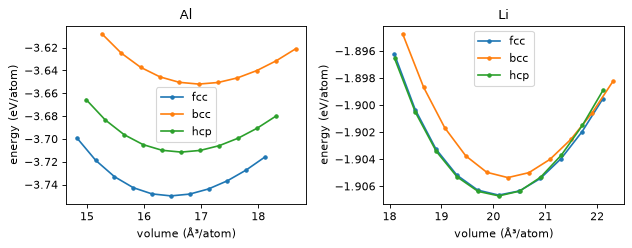

In [ ]:
eos = dict(zip(names, eos_batch(model, list(relaxed.values()), num_of_point=11, volume_range=0.1,
                               fit="birchmurnaghan")))
for (element, phase), r in eos.items():
    natoms = len(relaxed[element, phase])
    print(f"{element:6s} {phase:4s} V0 = {r['equilibrium_volume'] / natoms:6.2f} Å³/atom   "
          f"B0 = {r['equilibrium_bulk_modulus']:6.1f} GPa   B' = {r['equilibrium_b_prime']:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, element in zip(axes, ("Al", "Li")):
    for (el, phase), r in eos.items():
        if el == element:
            natoms = len(relaxed[el, phase])
            ax.plot(np.array(r["volume"]) / natoms, np.array(r["energy"]) / natoms, "o-", ms=3, label=phase)
    ax.set(title=element, xlabel="volume (Å³/atom)", ylabel="energy (eV/atom)")
    ax.legend()
fig.tight_layout()

## 5. Elastic constants: `elastic_batch`

The full 6×6 matrix from stress against strain (six strains, five points each, the atoms relaxed in every strained
cell), plus Voigt / Reuss / Hill moduli. Experiment for Al (0 K): C11 ≈ 114, C12 ≈ 62, C44 ≈ 32 GPa. The bulk
modulus from the elastic constants (B_H) and from the equation of state (B0) are two independent estimates of the
same quantity and should agree. A negative shear constant C' = (C11 − C12) / 2, as for bcc Al, flags a mechanically
unstable phase.

In [ ]:
elastic = dict(zip(names, elastic_batch(model, list(relaxed.values()), num_of_point=5)))

print("element phase   C11    C12    C13    C33    C44    B_H  B0(EOS)   G_H   (GPa)")
for (element, phase), r in elastic.items():
    C = r["C"]
    print(f"{element:7s} {phase:5s} {C[0, 0]:6.1f} {C[0, 1]:6.1f} {C[0, 2]:6.1f} {C[2, 2]:6.1f} {C[3, 3]:6.1f} "
          f"{r['BH']:6.1f} {eos[element, phase]['equilibrium_bulk_modulus']:6.1f} {r['GH']:7.1f}")

element phase   C11    C12    C13    C33    C44    B_H  B0(EOS)   G_H   (GPa)
Al      fcc    122.6   59.3   59.3  122.6   36.0   80.4   80.2    34.2
Al      bcc     39.9   83.5   83.5   39.9   38.1   69.0   69.1  -183.6
Al      hcp    111.2   62.9   48.0  114.2    8.4   72.6   72.8    17.2
Li      fcc     16.2   12.0   12.0   16.2   10.1   13.4   13.6     5.5
Li      bcc     16.6   14.2   14.2   16.6   12.3   15.0   13.6     5.3
Li      hcp     23.1   11.0    5.8   32.7    3.9   13.8   14.2     6.0
Al3Li   L12    107.0   40.4   40.4  107.0   33.4   62.6   62.4    33.4


## 6. Phonons: `phonons_batch`

`phonons_batch` computes phonons by finite displacements with [phonopy](https://phonopy.github.io/phonopy/): the
displaced supercells of all crystals go through one batch (by default supercells with all lattice-plane spacings ≥
10 Å), and the result is one `phonopy.Phonopy` per crystal, here used for the phonon density of states (DOS) and the
vibrational free energy at 300 K. bcc Al, which section 5 found mechanically unstable, has imaginary frequencies
(plotted as negative). The highest phonon frequency of fcc Al is about 9.7 THz in experiment. Other displacement
schemes: `phonopy_forces_batch`
([docs/properties.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/properties.md)). Many crystals from a
script: `python/examples/phonons/phonons_batch.py`.

In [ ]:
phonon_crystals = [("Al", "fcc"), ("Al", "bcc"), ("Li", "bcc"), ("Al3Li", "L12")]
phonons = dict(zip(phonon_crystals, phonons_batch(model, [relaxed[name] for name in phonon_crystals])))
for (element, phase), ph in phonons.items():
    print(f"{element:6s} {phase:4s} supercell {np.diag(ph.supercell_matrix).tolist()}: {len(ph.supercell)} atoms")

Al     fcc  supercell [5, 5, 5]: 125 atoms
Al     bcc  supercell [5, 5, 5]: 125 atoms
Li     bcc  supercell [5, 5, 5]: 125 atoms
Al3Li  L12  supercell [3, 3, 3]: 108 atoms


element phase  f_min (THz)  f_max (THz)  F_vib(300 K, meV/atom)   (the 20x20x20 mesh, without Gamma)
Al      fcc          0.38         9.55  -1.5
Al      bcc         -3.20         8.79  unstable
Li      bcc          0.66         9.95  1.1


Al3Li   L12          0.40        11.03  7.3


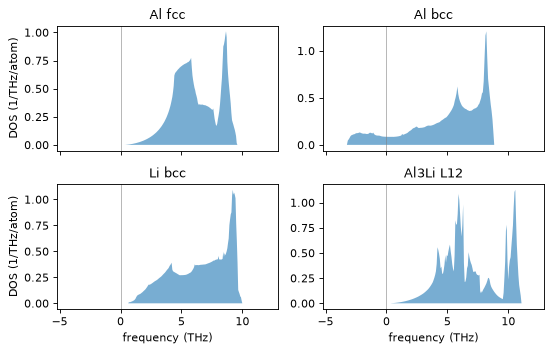

In [ ]:
imaginary_tol = -0.1    # THz: numerical noise of the acoustic modes near Gamma is not an instability

fig, axes = plt.subplots(2, 2, figsize=(7, 4.5), sharex=True)
print("element phase  f_min (THz)  f_max (THz)  F_vib(300 K, meV/atom)   (the 20x20x20 mesh, without Gamma)")
for ax, ((element, phase), ph) in zip(axes.flat, phonons.items()):
    ph.run_mesh([20, 20, 20])
    ph.run_total_dos()
    ph.run_thermal_properties(temperatures=[300])
    natoms = len(relaxed[element, phase])
    dos = ph.get_total_dos_dict()
    ax.fill_between(dos["frequency_points"], dos["total_dos"] / natoms, alpha=0.6)
    ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(f"{element} {phase}")

    freqs = ph.mesh.frequencies
    f_vib = ph.get_thermal_properties_dict()["free_energy"][0] * units.kJ / units.mol * 1000 / natoms    # meV/atom
    stability = "unstable" if freqs.min() < imaginary_tol else f"{f_vib:.1f}"
    print(f"{element:7s} {phase:5s} {freqs.min():11.2f} {freqs.max():12.2f}  {stability}")
for ax in axes[1]:
    ax.set_xlabel("frequency (THz)")
for ax in axes[:, 0]:
    ax.set_ylabel("DOS (1/THz/atom)")
fig.tight_layout()

## 7. High throughput: solute-vacancy binding in Al

A small screening run: a 108-atom fcc Al cell with one solute X, the same with a vacancy in the first or second
neighbour shell of X, and the pure and single-vacancy cells, 20 cells relaxed together in one `relax_batch`
(positions only, fixed cell at the model's lattice constant). The vacancy formation energy is
E_f(vac) = E(vac) − (N − 1)/N E(bulk), about 0.67 eV in experiment, and the binding energy
E_b(X, shell) = E(X) + E(vac) − E(X + vac) − E(bulk) is positive for attraction. The same scheme for 30 solutes
in W: `python/examples/relax/solute_vacancy_relax.py`.

In [ ]:
a_fcc = (4 * eos["Al", "fcc"]["equilibrium_volume"] / len(relaxed["Al", "fcc"])) ** (1 / 3)    # 4 atoms per cube
pure = bulk("Al", "fcc", a=a_fcc, cubic=True).repeat(3)
distances = pure.get_distances(0, range(len(pure)), mic=True)
shell_radii = {1: a_fcc / np.sqrt(2), 2: a_fcc}    # first and second neighbours in fcc
shell_site = {shell: int(np.argmin(abs(distances - r))) for shell, r in shell_radii.items()}    # neighbours of atom 0

solutes = ["Li", "Mg", "Si", "Cu", "Zn", "Sc"]
# keys: "bulk", "vac", the solute ("Mg"), the solute with a vacancy in a shell (("Mg", 1))
cells = {"bulk": pure, "vac": pure.copy()}
del cells["vac"][0]
for x in solutes:
    cells[x] = pure.copy()
    cells[x].symbols[0] = x
    for shell, site in shell_site.items():
        cells[x, shell] = cells[x].copy()
        del cells[x, shell][site]

vac_results = dict(zip(cells, relax_batch(model, list(cells.values()), fmax=0.01, max_steps=1000)))
e_cell = {key: r["energy"] for key, r in vac_results.items()}
print(f"{len(cells)} cells, {sum(len(c) for c in cells.values())} atoms, "
      f"all converged: {all(r['converged'] for r in vac_results.values())}")

n = len(pure)
e_vac_f = e_cell["vac"] - (n - 1) / n * e_cell["bulk"]
print(f"vacancy formation energy: {e_vac_f:.3f} eV\n")
print("X    E_b 1NN  E_b 2NN  (eV)")
for x in solutes:
    e_b = [e_cell[x] + e_cell["vac"] - e_cell[x, shell] - e_cell["bulk"] for shell in shell_site]
    print(f"{x:4s} {e_b[0]:7.3f}  {e_b[1]:7.3f}")

20 cells, 2147 atoms, all converged: True
vacancy formation energy: 0.702 eV

X    E_b 1NN  E_b 2NN  (eV)
Li    -0.046    0.023
Mg     0.011    0.013
Si     0.051   -0.005
Cu     0.029   -0.002
Zn     0.048   -0.010
Sc    -0.130    0.060


## 8. More

### Uncertainty: how far is a structure from the training data?

With UQ on (`calc.enable_uq()` for the calculator, `uq=True` for the batch functions) every evaluation also gives
the extrapolation grade `gamma` per atom and uncertainty estimates (`atomic_sigma`, `total_sigma`). Higher values
mean the structure is further from what the model was trained on. A scan of fcc Al from 0.2 to 5 times its
equilibrium volume, all in one `compute_batch(..., uq=True)`: gamma is lowest near equilibrium and grows under
strong compression and expansion, where the energy can no longer be trusted.

lowest max gamma 0.28 at 1.04 V0; 3.8 at 0.2 V0, 2.1 at 5 V0


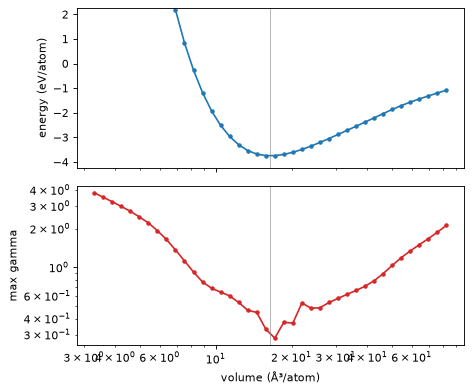

In [ ]:
volume_factors = np.geomspace(0.2, 5, 40)
v0 = relaxed["Al", "fcc"].get_volume() / len(relaxed["Al", "fcc"])
scan = []
for factor in volume_factors:
    atoms = relaxed["Al", "fcc"].copy()
    atoms.set_cell(atoms.cell * factor ** (1 / 3), scale_atoms=True)
    scan.append(atoms)

scan_results = compute_batch(model, scan, uq=True)
e_scan = np.array([r["energy"] / len(atoms) for r, atoms in zip(scan_results, scan)])
gamma_max = np.array([r["gamma"].max() for r in scan_results])

fig, (ax_e, ax_g) = plt.subplots(2, 1, figsize=(6, 5), sharex=True)
ax_e.plot(volume_factors * v0, e_scan, "o-", ms=3)
ax_e.set(ylabel="energy (eV/atom)", xscale="log", ylim=(e_scan.min() - 0.5, e_scan.min() + 6))
ax_g.plot(volume_factors * v0, gamma_max, "o-", ms=3, color="C3")
ax_g.set(xlabel="volume (Å³/atom)", ylabel="max gamma", xscale="log", yscale="log")
for ax in (ax_e, ax_g):
    ax.axvline(v0, color="gray", lw=0.5)    # the equilibrium volume
fig.tight_layout()
print(f"lowest max gamma {gamma_max.min():.2f} at {volume_factors[gamma_max.argmin()]:.2f} V0; "
      f"{gamma_max[0]:.1f} at {volume_factors[0]:g} V0, {gamma_max[-1]:.1f} at {volume_factors[-1]:g} V0")

### A short molecular dynamics run

The same calculator drives ASE's integrators: Langevin dynamics of a 108-atom fcc Al cell at 300 K, started from
the relaxed lattice constant.

108 atoms, mean temperature over the second half: 298 K


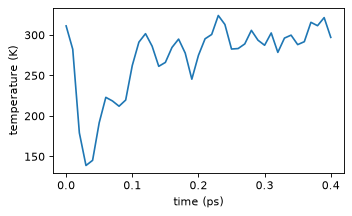

In [ ]:
timestep_fs, n_steps, sample_every = 2, 200, 5
v0_atom = eos["Al", "fcc"]["equilibrium_volume"] / len(relaxed["Al", "fcc"])
md_atoms = bulk("Al", "fcc", a=(4 * v0_atom) ** (1 / 3), cubic=True).repeat(3)    # 4 atoms per cube, 108 atoms
md_atoms.calc = calc

rng = np.random.default_rng(0)
MaxwellBoltzmannDistribution(md_atoms, temperature_K=300, rng=rng)
dyn = Langevin(md_atoms, timestep=timestep_fs * units.fs, temperature_K=300, friction=0.01 / units.fs,
               fixcm=False, rng=rng)    # fixcm=False: the setting ASE recommends
temperatures = []
dyn.attach(lambda: temperatures.append(md_atoms.get_temperature()), interval=sample_every)
dyn.run(n_steps)

time_ps = np.arange(len(temperatures)) * sample_every * timestep_fs / 1000
plt.figure(figsize=(4.5, 2.8))
plt.plot(time_ps, temperatures)
plt.xlabel("time (ps)")
plt.ylabel("temperature (K)")
plt.tight_layout()
second_half = temperatures[len(temperatures) // 2:]
print(f"{len(md_atoms)} atoms, mean temperature over the second half: {np.mean(second_half):.0f} K")

### Next

- [README](https://github.com/ICAMS/grace-runtime#use): the calculator, UQ and the batch functions in short.
- [docs/relax.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/relax.md) and
  [docs/properties.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/properties.md): all options of
  `relax_batch`, `eos_batch`, `elastic_batch` and `phonons_batch`; `relax_batch_iter` / `compute_batch_iter` stream
  results for datasets that do not fit in memory.
- [docs/advanced.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/advanced.md): threads
  (`GRACERuntimeCalculator(..., num_threads=4)`), GPUs (`device="cuda"` raises an error instead of falling back to
  the CPU), several calculators in one process.
- [docs/models.md](https://github.com/ICAMS/grace-runtime/blob/master/docs/models.md) and `grace-runtime models`:
  the foundation models.
- The command line: `grace-runtime info` (where calculations run), `grace-runtime relax` (batch relaxation of a
  file).